# Movie Recommendation Engine ? Part 2

This notebook builds a simple **content-based recommendation system** from movie genres and your ratings. Each step has its own explanation and code cell. Run the code cells from top to bottom.

**In brief:** movie genres become binary features, your ratings create a weighted genre profile, and every movie receives a score based on how well its genres match your profile.

## 1. Import libraries and load the data

We use `movies.csv` for movie titles and genres. `ratings.csv` is also loaded so you can inspect the ratings dataset; the personal ratings used by this Part 2 example are entered separately below.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

movies_df = pd.read_csv("movies.csv")
ratings_df = pd.read_csv("ratings.csv")

print(f"Movies: {movies_df.shape[0]:,} rows, {movies_df.shape[1]} columns")
print(f"Ratings: {ratings_df.shape[0]:,} rows, {ratings_df.shape[1]} columns")
display(movies_df.head())

Movies: 9,742 rows, 3 columns
Ratings: 100,836 rows, 4 columns


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [3]:
ratings_df.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## 2. Prepare movie titles and genre features

The movie titles in the CSV include release years, such as `Toy Story (1995)`. We extract the year and remove it from the title so that the titles entered below can be matched easily. Each genre is then converted into a 0/1 feature.

In [2]:
movies_df["year"] = movies_df["title"].str.extract(r"\((\d{4})\)\s*$")
movies_df["title"] = movies_df["title"].str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True)

genre_features = movies_df["genres"].str.get_dummies(sep="|")
genre_features = genre_features.drop(columns=["(no genres listed)"], errors="ignore")
genre_columns = genre_features.columns.tolist()

movies_copy = pd.concat(
    [movies_df[["movieId", "title", "genres", "year"]], genre_features],
    axis=1,
)

display(movies_copy[["movieId", "title", "genres", "year"] + genre_columns].head())

,movieId,title,genres,year,Action,Adventure,Animation,Children,Comedy,Crime,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,1995,0,1,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji,Adventure|Children|Fantasy,1995,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men,Comedy|Romance,1995,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale,Comedy|Drama|Romance,1995,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II,Comedy,1995,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


## 3. Enter your ratings

Change the titles and ratings in `user_input` to personalize the recommendations. Ratings are used as relative preference weights, so this example does not enforce a particular rating scale.

In [3]:
user_input = [
    {"title": "Grand Slam", "rating": 5.6},
    {"title": "Zero", "rating": 7},
    {"title": "Jumanji", "rating": 8.5},
    {"title": "Toy Story", "rating": 4.5},
]

movies_input = pd.DataFrame(user_input)
display(movies_input)

,title,rating
0,Grand Slam,5.6
1,Zero,7.0
2,Jumanji,8.5
3,Toy Story,4.5


## 4. Match your titles to movie IDs

Movie IDs let us connect the ratings to the genre features. Any title that has no exact match in the prepared movie list is shown separately; it is not silently substituted with a similarly named movie.

In [4]:
movie_lookup = movies_df[["movieId", "title", "genres", "year"]]
movies_input = movies_input.merge(movie_lookup, on="title", how="inner")

matched_titles = set(movies_input["title"])
missing_titles = [title for title in user_input if title["title"] not in matched_titles]

print(f"Matched titles: {len(movies_input)} of {len(user_input)}")
if missing_titles:
    print("Titles not found in movies.csv:")
    display(pd.DataFrame(missing_titles))

display(movies_input)

Matched titles: 2 of 4
Titles not found in movies.csv:


,title,rating
0,Grand Slam,5.6
1,Zero,7.0


,title,rating,movieId,genres,year
0,Jumanji,8.5,2,Adventure|Children|Fantasy,1995
1,Toy Story,4.5,1,Adventure|Animation|Children|Comedy|Fantasy,1995


## 5. Build your genre taste profile

For each matched movie, we multiply its genre indicators by your rating. Adding those weighted genre values creates a profile showing which genres best describe your preferences.

In [5]:
if movies_input.empty:
    raise ValueError("None of the entered titles were found in movies.csv; add at least one matching title.")

movies_user = movies_copy.loc[
    movies_copy["movieId"].isin(movies_input["movieId"])
].reset_index(drop=True)
user_genres = movies_user.set_index("movieId")[genre_columns]
ratings_for_user = movies_input.set_index("movieId").loc[movies_user["movieId"], "rating"]
UserProfile = user_genres.transpose().dot(ratings_for_user)

profile_table = UserProfile.rename("weight").to_frame()
display(profile_table.sort_values("weight", ascending=False))

,weight
Adventure,13.0
Fantasy,13.0
Children,13.0
Comedy,4.5
Animation,4.5
Action,0.0
Crime,0.0
Documentary,0.0
Drama,0.0
Film-Noir,0.0


## 6. Plot your taste profile

This bar chart makes the genre weights easier to compare. A higher bar means that genre contributed more to the profile built from your ratings.

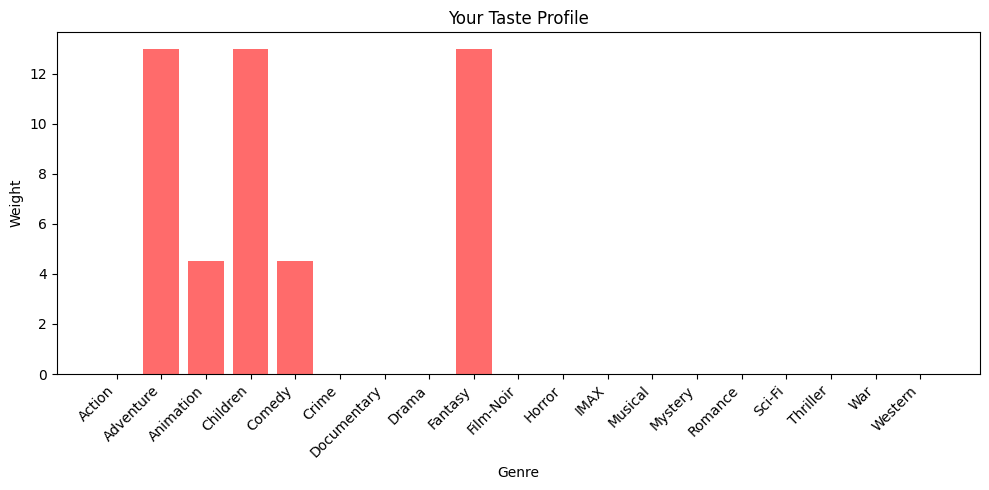

In [6]:
plt.figure(figsize=(10, 5))
plt.bar(UserProfile.index, UserProfile.values, color="#FF6B6B")
plt.title("Your Taste Profile")
plt.xlabel("Genre")
plt.ylabel("Weight")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 7. Score and rank movies

A movie's match score is the sum of its genre weights divided by the total profile weight. Higher scores indicate a stronger genre match. This is a relative match score, not a probability or predicted star rating.

In [7]:
profile_total = UserProfile.sum()
if profile_total == 0:
    raise ValueError("The taste profile has zero total weight; use at least one positive rating.")

genre_table = movies_copy.set_index("movieId")[genre_columns]
Recommendation_df = (genre_table.dot(UserProfile) / profile_total).sort_values(ascending=False)

movie_details = movies_df.set_index("movieId")[["title", "year", "genres"]]
top20 = Recommendation_df.head(20).rename("match_score").to_frame().join(movie_details)
display(top20[["title", "year", "genres", "match_score"]])

,title,year,genres,match_score
movieId,,,,
1,Toy Story,1995,Adventure|Animation|Children|Comedy|Fantasy,1.0
84637,Gnomeo & Juliet,2011,Adventure|Animation|Children|Comedy|Fantasy|Ro...,1.0
92348,Puss in Boots (Nagagutsu o haita neko),1969,Adventure|Animation|Children|Comedy|Fantasy|Ro...,1.0
91355,Asterix and the Vikings (Astérix et les Vikings),2006,Adventure|Animation|Children|Comedy|Fantasy,1.0
78637,Shrek Forever After (a.k.a. Shrek: The Final C...,2010,Adventure|Animation|Children|Comedy|Fantasy|IMAX,1.0
673,Space Jam,1996,Adventure|Animation|Children|Comedy|Fantasy|Sc...,1.0
65577,"Tale of Despereaux, The",2008,Adventure|Animation|Children|Comedy|Fantasy,1.0
4306,Shrek,2001,Adventure|Animation|Children|Comedy|Fantasy|Ro...,1.0
3114,Toy Story 2,1999,Adventure|Animation|Children|Comedy|Fantasy,1.0


## 8. Plot the top 10 picks

The chart displays the ten highest-ranked movies from the score table above. The recommendations use the same ratings and genre features shown in the previous steps.

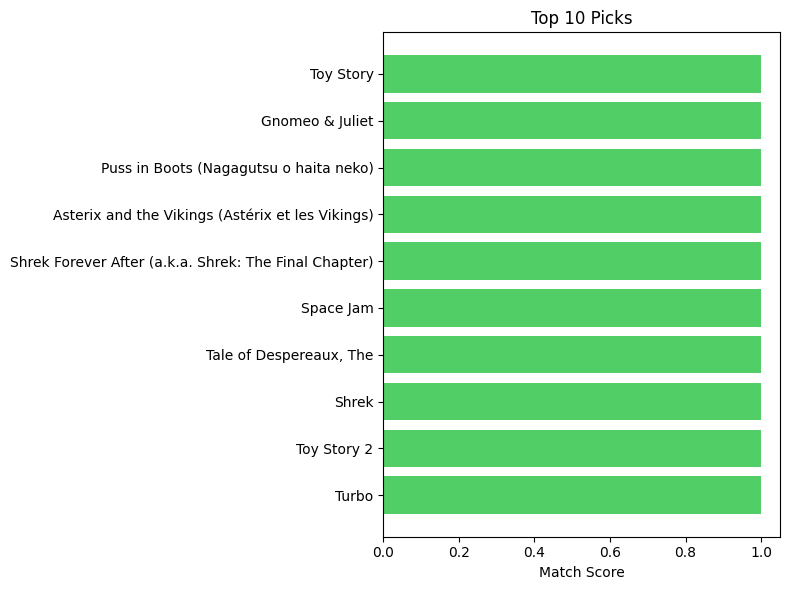

In [8]:
top10_scores = Recommendation_df.head(10)
top10_titles = movie_details.loc[top10_scores.index, "title"]

plt.figure(figsize=(8, 6))
plt.barh(top10_titles.iloc[::-1], top10_scores.values[::-1], color="#51CF66")
plt.title("Top 10 Picks")
plt.xlabel("Match Score")
plt.tight_layout()
plt.show()

## What the results mean

- The genre profile summarizes the preferences expressed by the matched titles and ratings.
- The ranked table lists movies with the strongest genre overlap, along with their match scores.
- Titles not available in `movies.csv` are reported in Step 4. Add a title that appears in the dataset if you want it included in the profile.

To try another profile, edit `user_input` in Step 3 and rerun the code cells below it.